# ER2026 — сравнение методов классификации букв семафора

Ноутбук читает **готовую ручную разметку** из `records/<recording_id>/<recording_id>.json` и движения из BVH.
Источник по умолчанию — **Noitom**. Разметчик запускается отдельно; этот ноутбук не меняет метки.
Анализ ограничен захватом движений.

Из корня проекта установите зависимости и выберите ядро `.venv`:
```powershell
.venv\Scripts\python.exe -m pip install -e ".[analysis,notebook,classification]"
.venv\Scripts\python.exe -m jupyterlab scripts/ER2026/processing/semaphore_classification.ipynb
```
Выполняйте ячейки сверху вниз. После добавления меток повторите загрузку и последующие ячейки.
Результаты сохраняются в `output/classification_experiments/`.

**Что измеряется:** распознавание букв внутри уже выделенных удержаний.
Неразмеченные участки, переходы и неизвестные позы не становятся отрицательными примерами.
Это пока не оценка непрерывного распознавания всей записи и не проверка на других модальностях.


In [1]:
from pathlib import Path
import sys
import os
import json
import platform
from datetime import datetime, timezone

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "scripts/ER2026/processing/motion.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из каталога репозитория ImuMotionCapture.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts.ER2026.paths import RECORDS_ROOT, OUTPUT_ROOT
LABELS_ROOT = None  # JSON beside each BVH; set a Path to use a shared directory
OUTPUT_DIR = OUTPUT_ROOT / "classification_experiments"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(OUTPUT_DIR / "matplotlib_cache"))

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
try:
    import sklearn
except ImportError as error:
    raise ImportError('Установите зависимости в ядро ноутбука: %pip install -e ".[analysis,notebook,classification]" из корня проекта.') from error
from IPython.display import display, Markdown
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from scripts.ER2026.processing.classification_experiments import (
    MODEL_NAMES, FEATURE_NAMES, build_dataset, make_splits, make_model, benchmark, split_membership)
from scripts.ER2026.processing.io import atomic_json

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": .2})
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 50)
def show_save(fig, name):
    fig.savefig(OUTPUT_DIR / (name + ".png"), dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python:", sys.executable)
print("scikit-learn:", sklearn.__version__, "| NumPy:", np.__version__, "| pandas:", pd.__version__)


Python: C:\Users\brody\Desktop\Work\MIPT\MotionCapture\ImuMotionCapture\.venv\Scripts\python.exe
scikit-learn: 1.9.1 | NumPy: 2.5.3 | pandas: 3.0.6


## 1. Настройки эксперимента

Для букв `INCLUDE_NEUTRAL=False`; при включении нейтральная поза становится отдельным классом.
`TRANSITION`, `BAD`, `UNKNOWN` и неподтверждённые интервалы исключаются всегда.
Е/Э объединяются: в словаре им соответствует одна поза.

В каждом окне берутся направления четырёх костей рук **относительно спины**.
`mean` — 12 средних координат; `mean_std` — те же 12 средних и 12 стандартных отклонений.
Это признаки положения и изменчивости позы, без вычитания углов Эйлера.

`auto` выбирает проверку по участникам, затем по записям, а при единственной записи — по временным блокам.
`SUBJECT_MAP` нужен, если один человек имеет несколько ID. Соответствие `P001` и `P001_mio`
не предполагается автоматически: при таких неоднозначных ID задайте подтверждённую карту.


In [2]:
SOURCE = "noitom"                  # noitom или custom; источники не смешиваются
RECORDING_IDS = None               # None = все размеченные записи; либо список ID
INCLUDE_NEUTRAL = False
WINDOW_S, STEP_S, TRIM_S = .25, .25, .10
VALIDATION_MODE = "auto"           # auto / subject / recording / blocked_time
N_TIME_BLOCKS = 5
PURGE_S = .5                       # удаление близких обучающих удержаний около проверочного блока
SUBJECT_MAP = None                 # например {"P001": "person_1", "P001_mio": "person_1"}
SEED = 42
FEATURE_SETS = ("mean", "mean_std")
MODELS = list(MODEL_NAMES)
INSPECT_MODEL, INSPECT_FEATURES = "RBF SVM", "mean_std"
FIT_FINAL_MODEL = False            # включить после осознанного выбора модели для дальнейшего использования


## 2. Загрузка размеченного датасета

Проверяются хеш выбранного BVH, метаданные записи, границы и пересечения интервалов.
Из каждого удержания обрезаются края `TRIM_S`; остаются только окна с полным числом отсчётов.
Таблица покажет, какие записи ещё не размечены и какие интервалы исключены.


In [3]:
dataset = build_dataset(RECORDS_ROOT, LABELS_ROOT, source=SOURCE,
    window_s=WINDOW_S, step_s=STEP_S, trim_s=TRIM_S,
    include_neutral=INCLUDE_NEUTRAL, recording_ids=RECORDING_IDS)
samples = dataset.samples
ready_holds = dataset.holds.loc[dataset.holds["status"] == "ready"].copy()
classes = sorted(samples["label"].unique())
display(dataset.inventory)
display(dataset.holds.groupby("status", as_index=False).agg(intervals=("hold_id", "size"), seconds=("duration_s", "sum")))
print(f"Удержаний: {len(ready_holds)}; окон: {len(samples)}; классов: {len(classes)}; "
      f"записей: {samples['recording_id'].nunique()}; ID участников: {samples['subject_id'].nunique()}")
if samples.empty:
    print("Пригодных окон пока нет. Добавьте разметку или проверьте длительность окон и обрезку границ.")


,recording_id,subject_id,source,intervals,usable_holds,windows,status
0,20261012_180237_255468_P001_SET01_92aa17,P001,noitom,100,82,209,ready
1,20261015_134311_929859_Alex_mio_SET01_b2c873,Alex_mio,noitom,0,0,0,not_annotated
2,20261015_135408_558790_Alex_mio_SET02_a567e2,Alex_mio,noitom,0,0,0,not_annotated
3,20261019_162022_434524_P003_SET01_25f342,P003,noitom,0,0,0,not_annotated
4,20261021_125211_697542_P003_mio_SET01_596859,P003_mio,noitom,0,0,0,not_annotated
5,20261021_130127_935575_P001_mio_SET01_012733,P001_mio,noitom,0,0,0,not_annotated
6,20261021_130813_079975_P001_mio_SET02_41c5e7,P001_mio,noitom,0,0,0,not_annotated


,status,intervals,seconds
0,neutral_disabled,18,95.720
1,ready,82,81.437


Удержаний: 82; окон: 209; классов: 10; записей: 1; ID участников: 1


## 3. Баланс классов и объём независимых примеров

Количество удержаний полезнее числа соседних окон для оценки покрытия класса.
Буква с одним удержанием не может присутствовать одновременно в обучении и независимой проверке.
Такие буквы остаются в оценке; для них будет явно показано отсутствие обучающих примеров.


,holds,windows,recordings,subject_ids
label,,,,
А,21,47,1,1
Б,6,14,1,1
В,7,15,1,1
Г,5,11,1,1
Д,6,16,1,1
Н,9,24,1,1
О,15,54,1,1
Т,11,25,1,1
Ц,1,2,1,1


**Классы менее чем с двумя удержаниями:**

,holds,windows,recordings,subject_ids
label,,,,
Ц,1,2,1,1
Ч,1,1,1,1


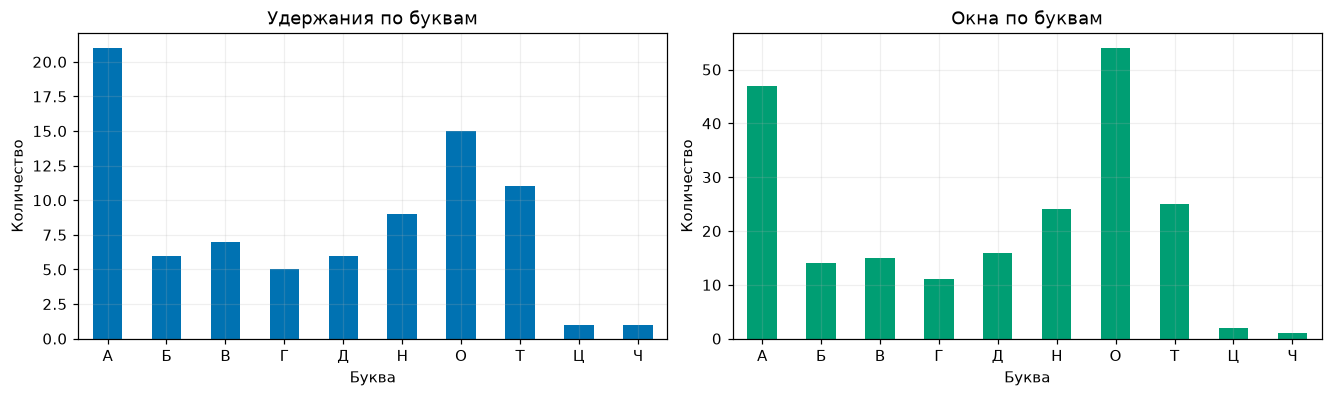

In [4]:
class_counts = ready_holds.groupby("label").agg(
    holds=("hold_id", "nunique"), windows=("windows", "sum"),
    recordings=("recording_id", "nunique"), subject_ids=("subject_id", "nunique"))
display(class_counts)
display(Markdown("**Классы менее чем с двумя удержаниями:**"))
display(class_counts.loc[class_counts["holds"] < 2])
if not class_counts.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
    class_counts["holds"].plot.bar(ax=axes[0], color="#0072B2", rot=0)
    class_counts["windows"].plot.bar(ax=axes[1], color="#009E73", rot=0)
    axes[0].set(title="Удержания по буквам", xlabel="Буква", ylabel="Количество")
    axes[1].set(title="Окна по буквам", xlabel="Буква", ylabel="Количество")
    show_save(fig, "01_class_balance")


## 4. Разбиение без перемешивания кадров

Все окна одного удержания попадают в одну проверочную часть.
Для `subject` и `recording` поочерёдно откладывается целый участник или запись.
Для `blocked_time` запись делится на равные временные блоки; удержание относится к блоку
по середине интервала. Из обучения удаляются целые удержания, близкие к проверочному блоку.

При единственной сессии это **предварительная проверка внутри сессии**. Она не измеряет перенос
на нового человека или день, и обучение может использовать время до и после проверочного блока.
Методы сравниваются на одинаковых разбиениях. Если после разделения меньше двух обучающих классов,
часть пропускается с причиной; доля проверенных удержаний показана в итоговой таблице.


In [5]:
folds, split_audit, actual_mode = make_splits(samples, mode=VALIDATION_MODE,
    n_blocks=N_TIME_BLOCKS, purge_s=PURGE_S, subject_map=SUBJECT_MAP)
display(split_audit)
print("Режим проверки:", actual_mode, "| пригодных частей:", len(folds))
if actual_mode == "blocked_time":
    display(Markdown("**Результаты относятся к новым временным блокам имеющихся сессий; перенос на новых людей не проверен.**"))
elif actual_mode == "recording":
    display(Markdown("**Отложены целые записи; один человек может встречаться с обеих сторон разделения.**"))
if not folds:
    print("Сравнение моделей пропущено: нужно больше независимых удержаний/записей и минимум два обучающих класса.")
membership = split_membership(samples, folds)


,fold,held_out,mode,status,reason,train_windows,test_windows,train_holds,test_holds,purged_windows,unseen_test_classes
0,1,time_block_1,blocked_time,ready,,159,50,68,14,0,Ц
1,2,time_block_2,blocked_time,ready,,164,45,66,16,0,
2,3,time_block_3,blocked_time,ready,,169,40,64,18,0,
3,4,time_block_4,blocked_time,ready,,175,34,66,16,0,
4,5,time_block_5,blocked_time,ready,,169,40,64,18,0,Ч


Режим проверки: blocked_time | пригодных частей: 5


**Результаты относятся к новым временным блокам имеющихся сессий; перенос на новых людей не проверен.**

## 5. Методы и фиксированные настройки

Сравниваем простой ориентир `Dummy`, ближайший центроид, kNN, логистическую регрессию,
линейный и RBF SVM, случайный лес. Для моделей, чувствительных к масштабу, `StandardScaler`
обучается **только на обучающей части** внутри Pipeline. kNN использует до пяти соседей.
Настройки фиксированы заранее; автоматического поиска по проверочным меткам нет.

Основная метрика — **macro-F1 по удержаниям**, где все буквы имеют одинаковый вес.
Предсказание удержания — большинство голосов его окон; при равенстве выбирается первый класс
в лексикографическом порядке. Дополнительно считаются accuracy и balanced accuracy.
Длинные удержания могут сильнее влиять на обучение через число окон, но каждое даёт один голос при оценке.


In [6]:
display(pd.DataFrame([{"model": name, "estimator": str(make_model(name, max(1, len(samples)), SEED))}
                      for name in MODELS]))
results = benchmark(dataset, folds, models=MODELS, feature_sets=FEATURE_SETS, seed=SEED, progress=print)
summary = results["summary"]
display(summary.round(4))
if not results["folds"].empty:
    reported_warnings = results["folds"].loc[results["folds"]["warnings"] != "", ["model", "features", "fold", "warnings"]]
    if not reported_warnings.empty:
        display(reported_warnings)


,model,estimator
0,Dummy,DummyClassifier(strategy='most_frequent')
1,Nearest centroid,"Pipeline(steps=[('standardscaler', StandardSca..."
2,kNN,"Pipeline(steps=[('standardscaler', StandardSca..."
3,Logistic regression,"Pipeline(steps=[('standardscaler', StandardSca..."
4,Linear SVM,"Pipeline(steps=[('standardscaler', StandardSca..."
5,RBF SVM,"Pipeline(steps=[('standardscaler', StandardSca..."
6,Random forest,RandomForestClassifier(class_weight='balanced_...


mean: Dummy
mean: Nearest centroid


mean: kNN
mean: Logistic regression


mean: Linear SVM


mean: RBF SVM
mean: Random forest


...

mean_std: kNN


mean_std: Logistic regression


mean_std: Linear SVM
mean_std: RBF SVM


mean_std: Random forest


,model,features,folds,windows,holds,hold_coverage,unseen_test_holds,fit_predict_s,window_accuracy,window_macro_f1,window_balanced_accuracy,hold_accuracy,hold_macro_f1,hold_balanced_accuracy
0,Logistic regression,mean,5,209,82,1.0,2,0.1923,0.9856,0.8000,0.8000,0.9756,0.8000,0.8000
1,Nearest centroid,mean,5,209,82,1.0,2,0.1052,0.9856,0.8000,0.8000,0.9756,0.8000,0.8000
2,RBF SVM,mean,5,209,82,1.0,2,0.0272,0.9856,0.8000,0.8000,0.9756,0.8000,0.8000
3,Random forest,mean,5,209,82,1.0,2,2.5570,0.9856,0.8000,0.8000,0.9756,0.8000,0.8000
4,Random forest,mean_std,5,209,82,1.0,2,2.5337,0.9856,0.7943,0.8000,0.9756,0.7917,0.8000
5,kNN,mean,5,209,82,1.0,2,0.0234,0.9856,0.7943,0.8000,0.9756,0.7917,0.8000
6,Linear SVM,mean,5,209,82,1.0,2,0.0377,0.9856,0.7917,0.8000,0.9756,0.7909,0.8000
7,Linear SVM,mean_std,5,209,82,1.0,2,0.0428,0.9761,0.7812,0.7867,0.9756,0.7833,0.8000
8,Logistic regression,mean_std,5,209,82,1.0,2,0.1278,0.9665,0.7718,0.7793,0.9634,0.7699,0.7833
9,RBF SVM,mean_std,5,209,82,1.0,2,0.0354,0.9569,0.7618,0.7631,0.9512,0.7670,0.7722


## 6. Сравнение признаков и моделей

Таблица объединяет только предсказания на отложенных частях.
`hold_coverage` — доля пригодных удержаний, попавших в проверку.
`unseen_test_holds` — число удержаний букв, которых не было в соответствующей обучающей части.
Macro-F1 использует общий набор классов, balanced accuracy усредняет полноту присутствующих истинных классов.


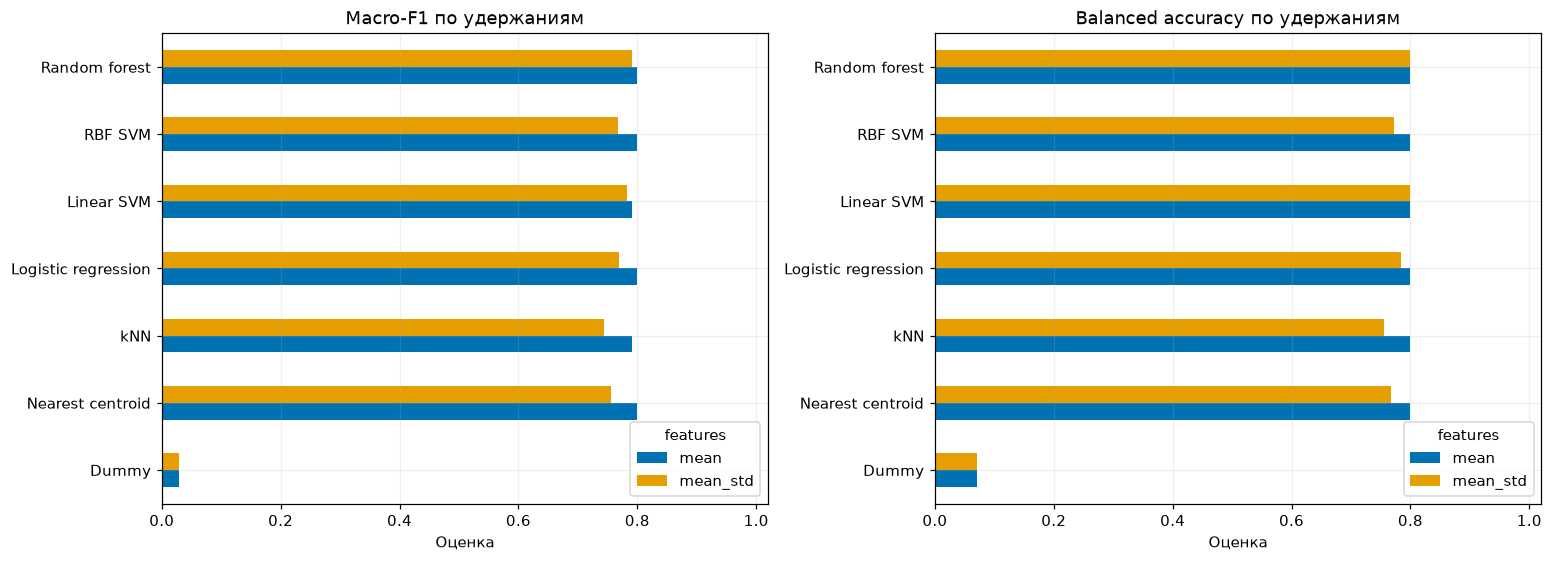

In [7]:
if not summary.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
    for ax, metric, title in zip(axes, ("hold_macro_f1", "hold_balanced_accuracy"),
                                 ("Macro-F1 по удержаниям", "Balanced accuracy по удержаниям")):
        table = summary.pivot(index="model", columns="features", values=metric).reindex(MODELS)
        table.plot.barh(ax=ax, color=["#0072B2", "#E69F00"])
        ax.set(title=title, xlabel="Оценка", ylabel="", xlim=(0, 1.02))
    show_save(fig, "02_model_comparison")
else:
    print("Пока нет результатов сравнения; см. аудит разбиения выше.")


## 7. Матрица ошибок выбранного метода

Для подробного просмотра используйте `INSPECT_MODEL` и `INSPECT_FEATURES` в параметрах.
Матрица и отчёт ниже относятся к целым удержаниям, а не к соседним кадрам.
Выбор лучшей конфигурации по этой таблице является выбором модели по валидации;
его итоговый результат необходимо проверить на отдельной новой записи.


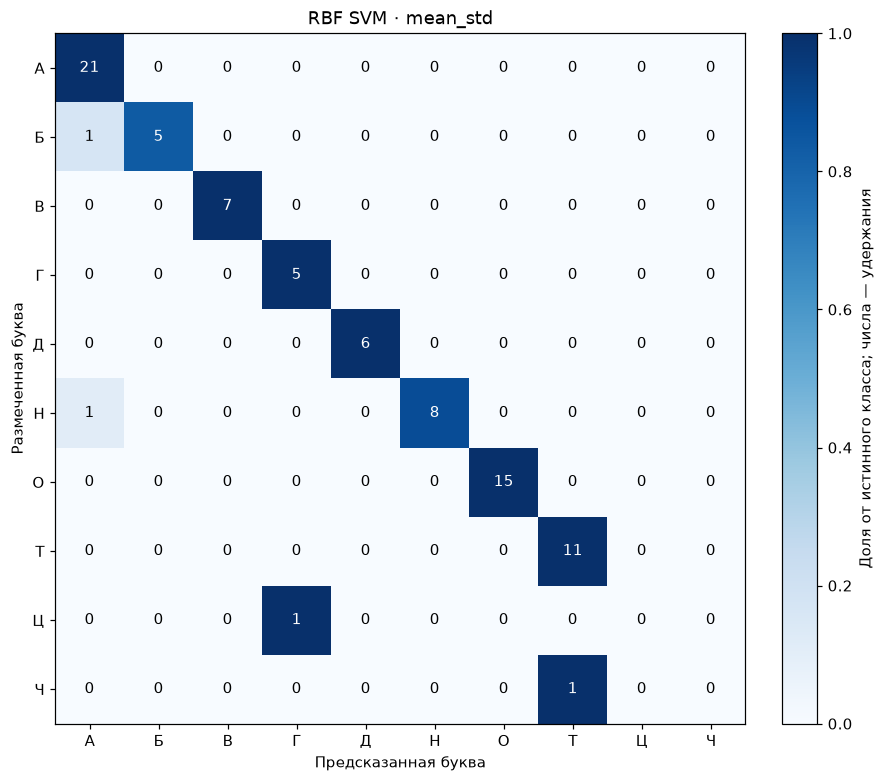

,label,precision,recall,f1,holds
0,А,0.913,1.000,0.955,21
1,Б,1.000,0.833,0.909,6
2,В,1.000,1.000,1.000,7
3,Г,0.833,1.000,0.909,5
4,Д,1.000,1.000,1.000,6
5,Н,1.000,0.889,0.941,9
6,О,1.000,1.000,1.000,15
7,Т,0.917,1.000,0.957,11
8,Ц,0.000,0.000,0.000,1
9,Ч,0.000,0.000,0.000,1


In [8]:
chosen = results["holds"]
if not chosen.empty:
    chosen = chosen.loc[(chosen["model"] == INSPECT_MODEL) & (chosen["features"] == INSPECT_FEATURES)].copy()
class_report = pd.DataFrame()
if not chosen.empty:
    cm = confusion_matrix(chosen["label"], chosen["predicted"], labels=classes)
    support = cm.sum(axis=1, keepdims=True)
    norm = np.divide(cm, support, out=np.zeros_like(cm, dtype=float), where=support != 0)
    fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
    im = ax.imshow(norm, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(len(classes)), classes)
    ax.set_yticks(range(len(classes)), classes)
    ax.set(xlabel="Предсказанная буква", ylabel="Размеченная буква", title=f"{INSPECT_MODEL} · {INSPECT_FEATURES}")
    ax.grid(False)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if norm[i, j] > .5 else "black")
    fig.colorbar(im, ax=ax, label="Доля от истинного класса; числа — удержания")
    show_save(fig, "03_confusion_holds")
    precision, recall, f1, support = precision_recall_fscore_support(
        chosen["label"], chosen["predicted"], labels=classes, zero_division=0)
    class_report = pd.DataFrame({"label": classes, "precision": precision, "recall": recall, "f1": f1, "holds": support})
    display(class_report.round(3))
else:
    print("Для выбранной модели и признаков нет проверочных предсказаний.")


## 8. Ошибки и их положение во времени

`vote_fraction` — доля окон, проголосовавших за выбранный класс, **не вероятность правильности**.
`unseen_in_train=True` выделяет случаи без обучающих примеров этой буквы.
Для пересмотра откройте указанную запись и интервал в отдельном аннотаторе.


,recording_id,start_s,end_s,label,predicted,vote_fraction,unseen_in_train
741,20261012_180237_255468_P001_SET01_92aa17,9.180,10.020,Ц,Г,1.0,True
765,20261012_180237_255468_P001_SET01_92aa17,105.817,106.714,Б,А,0.5,False
795,20261012_180237_255468_P001_SET01_92aa17,223.824,224.720,Н,А,0.5,False
807,20261012_180237_255468_P001_SET01_92aa17,255.960,256.660,Ч,Т,1.0,True


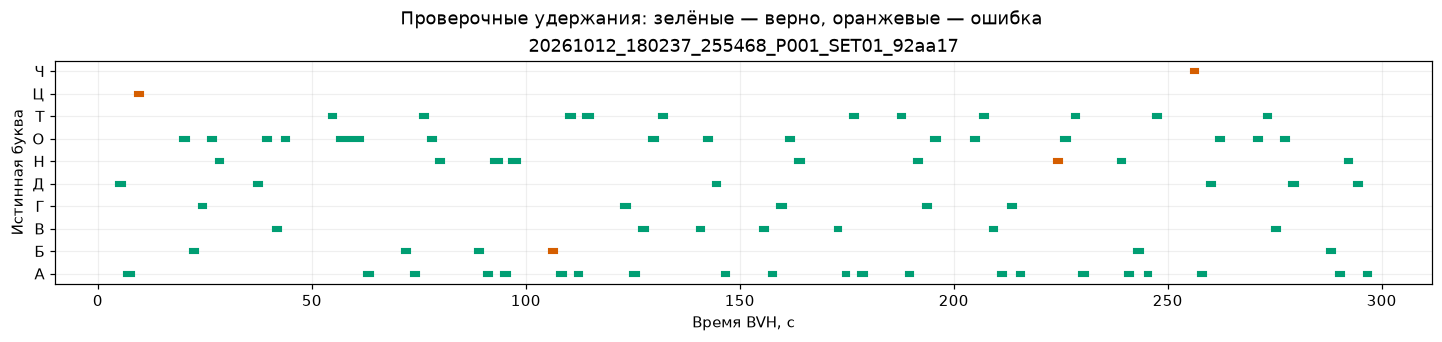

In [9]:
errors = pd.DataFrame()
if not chosen.empty:
    errors = chosen.loc[chosen["label"] != chosen["predicted"]].sort_values(["recording_id", "start_s"])
    display(errors[["recording_id", "start_s", "end_s", "label", "predicted", "vote_fraction", "unseen_in_train"]])
    recording_ids = chosen["recording_id"].unique()
    fig, axes = plt.subplots(len(recording_ids), 1, figsize=(13, 3 * len(recording_ids)), squeeze=False, layout="constrained")
    for ax, rid in zip(axes[:, 0], recording_ids):
        part = chosen.loc[chosen["recording_id"] == rid]
        for _, hold in part.iterrows():
            y = classes.index(hold["label"])
            good = hold["label"] == hold["predicted"]
            ax.plot([hold["start_s"], hold["end_s"]], [y, y], lw=4, color="#009E73" if good else "#D55E00")
        ax.set_yticks(range(len(classes)), classes)
        ax.set(title=rid, xlabel="Время BVH, с", ylabel="Истинная буква")
    fig.suptitle("Проверочные удержания: зелёные — верно, оранжевые — ошибка")
    show_save(fig, "04_errors_over_time")


## 9. Сохранение воспроизводимых результатов

Сохраняются настройки, версии библиотек, хеши BVH/разметки, состав частей, признаки,
предсказания окон и удержаний, метрики моделей и отчёт по выбранному методу.
Повторный запуск обновляет файлы в `OUTPUT_DIR`; для отдельного эксперимента задайте другой каталог.


In [10]:
config = dict(source=SOURCE, recording_ids=RECORDING_IDS, include_neutral=INCLUDE_NEUTRAL,
    window_s=WINDOW_S, step_s=STEP_S, trim_s=TRIM_S, requested_validation=VALIDATION_MODE,
    actual_validation=actual_mode, n_time_blocks=N_TIME_BLOCKS, purge_s=PURGE_S,
    subject_map=SUBJECT_MAP, seed=SEED, feature_sets=list(FEATURE_SETS), models=list(MODELS))
tables = {"inventory": dataset.inventory, "intervals": dataset.holds, "windows": samples,
    "class_counts": class_counts.reset_index(), "split_audit": split_audit,
    "split_membership": membership, "model_comparison": summary, "fold_metrics": results["folds"],
    "window_predictions": results["windows"], "hold_predictions": results["holds"],
    "selected_class_report": class_report, "selected_errors": errors}
for name, table in tables.items():
    table.to_csv(OUTPUT_DIR / (name + ".csv"), index=False, encoding="utf-8-sig")
np.savez_compressed(OUTPUT_DIR / "features.npz", mean=dataset.features["mean"],
                    mean_std=dataset.features["mean_std"], feature_names=np.asarray(FEATURE_NAMES))
report = dict(generated_at_utc=datetime.now(timezone.utc).isoformat(), config=config,
    versions={"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
              "scipy": scipy.__version__, "scikit_learn": sklearn.__version__},
    manifest=dataset.manifest, classes=classes, windows=len(samples), holds=len(ready_holds),
    inspection=dict(model=INSPECT_MODEL, features=INSPECT_FEATURES),
    models={name: str(make_model(name, max(1, len(samples)), SEED)) for name in MODELS},
    scores=summary.to_dict("records"), splits=split_audit.to_dict("records"),
    scope="Mocap pose classification inside reviewed holds; no continuous detection or other modalities",
    independent_final_test=False)
atomic_json(OUTPUT_DIR / "experiment.json", report)
print("Результаты:", OUTPUT_DIR)


Результаты: C:\Users\brody\Desktop\Work\MIPT\MotionCapture\ImuMotionCapture\scripts\ER2026\output\classification_experiments


## 10. Необязательное обучение выбранной модели на всех метках

По умолчанию выключено. После выбора метода установите `FIT_FINAL_MODEL=True` и повторите ячейку.
Это подготовка модели для использования, а не дополнительная оценка качества.
Pipeline сохраняется в `final_model.joblib` с параметрами признаков и версиями библиотек;
это отдельный формат от NumPy-модели команды `processing train`.


In [11]:
if FIT_FINAL_MODEL:
    if len(classes) < 2:
        print("Нужно хотя бы два размеченных класса для финальной модели.")
    else:
        import joblib
        final_model = make_model(INSPECT_MODEL, len(samples), SEED)
        final_model.fit(dataset.features[INSPECT_FEATURES], samples["label"].to_numpy())
        bundle = dict(estimator=final_model, features=INSPECT_FEATURES,
            feature_names=FEATURE_NAMES[:12] if INSPECT_FEATURES == "mean" else FEATURE_NAMES,
            config=config, versions=report["versions"], classes=classes, manifest=dataset.manifest)
        joblib.dump(bundle, OUTPUT_DIR / "final_model.joblib")
        print("Сохранена модель:", OUTPUT_DIR / "final_model.joblib")
else:
    print("Финальная модель не сохранялась: FIT_FINAL_MODEL=False.")


Финальная модель не сохранялась: FIT_FINAL_MODEL=False.


## Как продолжать эксперимент

Добавляйте повторения редких букв, записи других дней и людей, затем переходите от временных блоков
к проверке по записям и участникам. Новую запись для окончательного теста не используйте для выбора
признаков, модели и её настроек. При подборе гиперпараметров нужен внутренний групповой цикл внутри
обучающей части; этот ноутбук пока сравнивает фиксированные конфигурации.

Неразмеченные интервалы не равны `NEUTRAL`. Для работы на непрерывной записи потребуется отдельно
проверить детектор удержаний, переходов и отказ от неизвестных поз.

Методические ссылки:
[групповая перекрёстная проверка](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data),
[предотвращение утечки данных и Pipeline](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
